# Label Spreading vs self-training vs SVM on iris: sklearn vs Moxie

**Reference example:** `../scikit-learn/examples/semi_supervised/plot_semi_supervised_versus_svm_iris.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/semi_supervised/plot_semi_supervised_versus_svm_iris.html)).

**Scenario:** the first two iris features with 10 %, 30 % and 100 % of the labels. `LabelSpreading()` (default RBF
graph, `gamma=20`) and `SelfTrainingClassifier(CalibratedClassifierCV(SVC(gamma=0.5)))` are drawn as
`predict_proba` decision regions, and `predict_proba` is explained by hand for both estimators.

**Adaptations:**
- `DecisionBoundaryDisplay` is a plotting helper. Python builds the same 100×100 grid
  (feature range ± 1); Moxie evaluates `predict_proba` on it in Mojo, and both sides are drawn with `contourf`.
- **Self-training base estimator:** Moxie has no `CalibratedClassifierCV(SVC)` that can serve as a self-training base
  (no SVC `CalibrationEstimator` adapter, calibration PR #11 part 1, and no generic self-training adapter, this
  family's tracking PR part 1). The self-training panels use `GaussianNB()` through `GaussianNBAdapter` on both sides,
  and the calibrated SVC is recorded as a GAP.
- Extra composition checks: `make_pipeline(StandardScaler(), LabelSpreading())`, `clone`, and
  `cross_val_score(LabelSpreading(), X, y_30, cv=KFold(5))` through `moxie.model_selection`. Expected-failure cells show
  `kernel="knn"` (from `plot_label_propagation_structure.py`) and `SelfTrainingClassifier` as a pipeline step.

**Determinism:** deterministic (fixed `RandomState(42)` label mask, closed-form graph, GaussianNB), so learned
attributes and probabilities are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("semi_supervised/plot_semi_supervised_versus_svm_iris")

## 1. scikit-learn (Python reference)

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
from sklearn.semi_supervised import LabelSpreading, SelfTrainingClassifier

iris = load_iris()

X = iris.data[:, :2]
y = iris.target

rng = np.random.RandomState(42)
y_rand = rng.rand(y.shape[0])
y_10 = np.copy(y)
y_10[y_rand > 0.1] = -1  # set random samples to be unlabeled
y_30 = np.copy(y)
y_30[y_rand > 0.3] = -1

ls10 = (LabelSpreading().fit(X, y_10), y_10, "LabelSpreading with 10% labeled data")
ls30 = (LabelSpreading().fit(X, y_30), y_30, "LabelSpreading with 30% labeled data")
ls100 = (LabelSpreading().fit(X, y), y, "LabelSpreading with 100% labeled data")

base_classifier = GaussianNB()  # adapted: CalibratedClassifierCV(SVC(gamma=0.5, random_state=42))
st10 = (SelfTrainingClassifier(base_classifier).fit(X, y_10), y_10, "Self-training with 10% labeled data")
st30 = (SelfTrainingClassifier(base_classifier).fit(X, y_30), y_30, "Self-training with 30% labeled data")
rbf_svc = (base_classifier.fit(X, y), y, "GaussianNB\n(equivalent to Self-training with 100% labeled data)")

# DecisionBoundaryDisplay's default grid: 100 points per axis over the feature range +- 1.
x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100),
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 100))
grid = np.c_[x0.ravel(), x1.ravel()]
classifiers = (ls10, st10, ls30, st30, ls100, rbf_svc)
sk_grid = [clf.predict_proba(grid) for clf, _, _ in classifiers]

from sklearn.metrics.pairwise import rbf_kernel

ls = ls100[0]  # fitted LabelSpreading instance
x_query = np.array([[3.5, 1.5]])  # point in the soft blue region
W = rbf_kernel(x_query, X, gamma=ls.gamma)  # `gamma=20` by default
probs = np.dot(W, ls.label_distributions_)
probs /= probs.sum(axis=1, keepdims=True)
print("Manual:", probs)
print("API   :", ls.predict_proba(x_query))
st = st10[0]
print("Manual:", st.estimator_.predict_proba(x_query))
print("API   :", st.predict_proba(x_query))

# Composition references.
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
sk_pipe = make_pipeline(StandardScaler(), LabelSpreading()).fit(X, y_30)
sk_pipe_proba = sk_pipe.predict_proba(X)
sk_cv = cross_val_score(LabelSpreading(), X, y_30, cv=KFold(5))
print("cross_val_score:", sk_cv)
nb.share(X=X, y=y, y_10=y_10, y_30=y_30, grid=grid, x_query=x_query)

Manual: [[0.95561963 0.03149965 0.01288071]]
API   : [[0.95561963 0.03149965 0.01288071]]
Manual: [[7.11216365e-03 9.92887836e-01 3.77469618e-13]]
API   : [[7.11216365e-03 9.92887836e-01 3.77469618e-13]]
cross_val_score: [0.4        0.26666667 0.1        0.26666667 0.06666667]


## 2. Moxie (native Mojo)

In [3]:
%%mojo iris_semi_supervised
from numojo import NDArray, Shape, Item
from moxie.base import clone
from moxie._nb_gaussian import GaussianNB
from moxie.preprocessing import StandardScaler
from moxie.pipeline import make_pipeline
from moxie.semi_supervised import LabelSpreading, SelfTrainingClassifier, GaussianNBAdapter
from moxie_nb_io import load, load_ints, save, save_ints


def main() raises:
    var X = load("X")
    var grid = load("grid")
    var x_query = load("x_query")
    var names = List[String](["10", "30", "100"])
    var targets = List[List[Int]]([load_ints("y_10"), load_ints("y_30"), load_ints("y")])
    for k in range(3):
        var ls = LabelSpreading()
        _ = ls.fit(X, targets[k])
        save("ls" + names[k] + "_dist", ls.label_distributions_)
        save_ints("ls" + names[k] + "_trans", ls.transduction_)
        save_ints("ls" + names[k] + "_n_iter", [ls.n_iter_])
        save("ls" + names[k] + "_grid", ls.predict_proba(grid))
        if k == 2:
            save("ls_query", ls.predict_proba(x_query))
    for k in range(2):
        var base = GaussianNBAdapter(GaussianNB())
        var st = SelfTrainingClassifier[type_of(base)](base.copy())
        _ = st.fit(X, targets[k])
        save_ints("st" + names[k] + "_labeled_iter", st.labeled_iter_)
        save_ints("st" + names[k] + "_n_iter", [st.n_iter_])
        save("st" + names[k] + "_grid", st.predict_proba(grid))
        if k == 0:
            save("st_query", st.predict_proba(x_query))
            save("st_estimator_query", st.estimator_.value().predict_proba(x_query))
    var gnb = GaussianNB()
    _ = gnb.fit(X, targets[2])
    save("gnb_grid", gnb.predict_proba(grid))

    var pipe = make_pipeline(StandardScaler(), LabelSpreading())
    _ = pipe.fit(X, targets[1])
    save("pipe_proba", pipe.predict_proba(X))
    var pipe_clone = clone(pipe)
    print("pipeline clone fitted before fit:", pipe_clone.__sklearn_is_fitted__())
    _ = pipe_clone.fit(X, targets[1])
    save("pipe_clone_proba", pipe_clone.predict_proba(X))

pipeline clone fitted before fit: False


In [4]:
%%mojo iris_cross_val_score
from numojo import NDArray, Shape, Item
from moxie.semi_supervised import LabelSpreading
from moxie.model_selection import KFold, IndexArray, IndexSplit, cross_val_score
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie_nb_io import load, load_ints, save

comptime Dense = NDArray[DType.float64]
comptime Model = LabelSpreading[]


struct Accuracy(TypedScorer):
    # scoring=None: the estimator's own score (accuracy).
    comptime Estimator = Model
    comptime Input = Dense
    comptime Target = List[Int]
    comptime Metadata = Optional[Int]

    def __init__(out self):
        pass

    def score(self, estimator: Model, X: Dense, y: List[Int], metadata: Optional[Int]) raises -> Float64:
        return estimator.score(X, y)


struct Rows(CVAdapter):
    comptime Scorer = Accuracy

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: List[Int]) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        var out = Dense(Shape(rows.size, X.shape[1]))
        for i in range(rows.size):
            for j in range(X.shape[1]):
                out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
        return out^

    def target_rows(self, y: List[Int], rows: IndexArray) raises -> List[Int]:
        var out = List[Int]()
        for i in range(rows.size):
            out.append(y[Int(rows[Item(i)])])
        return out^

    def metadata_rows(self, metadata: Optional[Int], rows: IndexArray) raises -> Optional[Int]:
        return None

    def fit(self, mut estimator: Model, X: Dense, y: List[Int], metadata: Optional[Int]) raises:
        _ = estimator.fit(X, y)


def main() raises:
    var X = load("X")
    var y_30 = load_ints("y_30")
    var cursor = KFold(5).split(X.shape[0])
    var folds = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        folds.append(pair.value().copy())
    save("cv", cross_val_score[Rows](LabelSpreading(), X, y_30, Rows(), Accuracy(), folds, None, None))

### Unsupported steps

`kernel="knn"` (used by `plot_label_propagation_structure.py`) is deferred and must fail clearly at `fit`:

In [5]:
%%mojo knn_kernel --expect-fail
from moxie.semi_supervised import LabelSpreading
from moxie_nb_io import load, load_ints


def main() raises:
    var label_spread = LabelSpreading(kernel="knn", alpha=0.8)
    _ = label_spread.fit(load("X"), load_ints("y_30"))

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: ValueError: supported kernels are rbf and typed callable; knn is deferred



`SelfTrainingClassifier` is not a `SupervisedEstimator & Predictor` (its `predict` exists only when the adapter supports it), so it cannot end a `Pipeline`, unlike sklearn's `make_pipeline(StandardScaler(), SelfTrainingClassifier(...))`:

In [6]:
%%mojo self_training_pipeline --expect-fail
from moxie._nb_gaussian import GaussianNB
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.semi_supervised import SelfTrainingClassifier, GaussianNBAdapter
from moxie_nb_io import load, load_ints


def main() raises:
    var base = GaussianNBAdapter(GaussianNB())
    var pipe = make_pipeline(StandardScaler(), SelfTrainingClassifier[type_of(base)](base.copy()))
    _ = pipe.fit(load("X"), load_ints("y_30"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/semi_supervised/plot_semi_supervised_versus_svm_iris/self_training_pipeline.mojo:10:85: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'SelfTrainingClassifier[GaussianNBAdapter]' to 'E', argument type 'SelfTrainingClassifier[GaussianNBAdapter]' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), SelfTrainingClassifier[type_of(base)](base.copy()))
               ~~~~~~~~~~~~~                   ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/semi_supervised/plot_semi_supervised_versus_svm_iris/self_training_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/

## 3. Side by side and parity

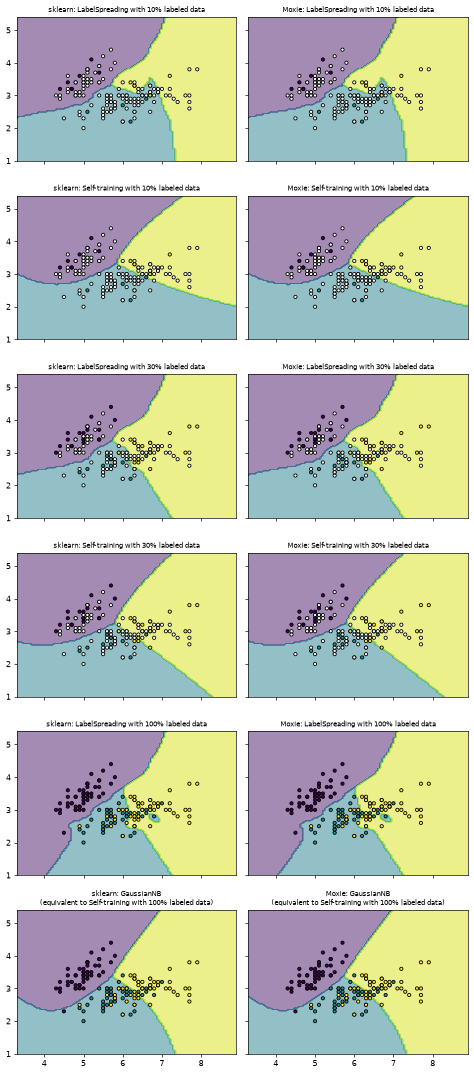

In [7]:
mx = nb.results["iris_semi_supervised"]
mx_grid = [mx["ls10_grid"], mx["st10_grid"], mx["ls30_grid"], mx["st30_grid"], mx["ls100_grid"], mx["gnb_grid"]]
fig, axes = plt.subplots(nrows=6, ncols=2, sharex=True, sharey=True, figsize=(8, 18), dpi=60)
for row, ((clf, y_train, title), skp, mxp) in enumerate(zip(classifiers, sk_grid, mx_grid)):
    for col, (name, p) in enumerate([("sklearn", skp), ("Moxie", mxp)]):
        ax = axes[row, col]
        ax.contourf(x0, x1, np.argmax(p, axis=1).reshape(x0.shape), alpha=0.5, cmap="viridis")
        colors = ["white" if label == -1 else plt.cm.viridis(label / 2) for label in y_train]
        ax.scatter(X[:, 0], X[:, 1], c=colors, edgecolor="black", s=15)
        ax.set_title(f"{name}: {title}", fontsize=8)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=sk_grid[0][:5], moxie=mx_grid[0][:5])

In [8]:
F64 = "Float64 RBF graph and diffusion; BLAS GEMM and NumPy pairwise sums vs native reduction order"
GNB = "GaussianNB Float64 log-likelihoods; exp/log-sum-exp rounding (family GaussianNB parity bound is 2e-9)"
for name, (clf, _, _) in zip(["10", "30", "100"], [ls10, ls30, ls100]):
    nb.compare(f"LabelSpreading {name}% n_iter_", clf.n_iter_, mx[f"ls{name}_n_iter"][0], exact=True)
    nb.compare(f"LabelSpreading {name}% label_distributions_", clf.label_distributions_, mx[f"ls{name}_dist"],
               rtol=1e-9, atol=1e-12, reason=F64)
    nb.compare(f"LabelSpreading {name}% transduction_", clf.transduction_, mx[f"ls{name}_trans"], exact=True)
for name, (clf, _, _), skp in zip(["10", "30"], [st10, st30], [sk_grid[1], sk_grid[3]]):
    nb.compare(f"SelfTraining {name}% labeled_iter_", clf.labeled_iter_, mx[f"st{name}_labeled_iter"], exact=True)
    nb.compare(f"SelfTraining {name}% n_iter_", clf.n_iter_, mx[f"st{name}_n_iter"][0], exact=True)
    nb.compare(f"SelfTraining {name}% predict_proba(grid)", skp, mx[f"st{name}_grid"], rtol=1e-7, atol=1e-9, reason=GNB)
for name, i in [("10", 0), ("30", 2), ("100", 4)]:
    # Far grid corners have affinities that underflow to 0 for every training point; both sides give NaN (0/0).
    nb.compare(f"LabelSpreading {name}% predict_proba(grid)", sk_grid[i], mx[f"ls{name}_grid"], rtol=1e-8, atol=1e-11,
               reason=F64 + "; grid points far from the data normalise tiny affinity sums")
nb.compare("GaussianNB 100% predict_proba(grid)", sk_grid[5], mx["gnb_grid"], rtol=1e-7, atol=1e-9, reason=GNB)
nb.compare("LabelSpreading predict_proba(x_query) vs manual rbf_kernel formula", probs, mx["ls_query"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("SelfTraining predict_proba delegates to estimator_", mx["st_estimator_query"], mx["st_query"], exact=True)
nb.compare("SelfTraining predict_proba(x_query)", st.predict_proba(x_query), mx["st_query"], rtol=1e-7, atol=1e-9, reason=GNB)
nb.compare("make_pipeline(StandardScaler, LabelSpreading).predict_proba", sk_pipe_proba, mx["pipe_proba"], rtol=1e-9, atol=1e-12,
           reason=F64 + "; StandardScaler variance reduction order")
nb.compare("clone(pipeline) refit", mx["pipe_proba"], mx["pipe_clone_proba"], exact=True)
nb.compare("cross_val_score(LabelSpreading, KFold(5))", sk_cv, nb.results["iris_cross_val_score"]["cv"], exact=True)
nb.note("CalibratedClassifierCV(SVC) self-training base", "GAP",
        "no SVC CalibrationEstimator adapter (calibration PR #11 part 1) and no generic self-training adapter for Moxie "
        "classifiers (semi_supervised tracking PR part 1); GaussianNB substituted on both sides")
nb.note("kernel='knn'", "GAP", "deferred and documented: fit raises 'supported kernels are rbf and typed callable; knn is deferred' "
        "(expected-failure cell above); blocks plot_label_propagation_structure.py")
nb.note("SelfTrainingClassifier as a Pipeline step", "GAP", "not a SupervisedEstimator & Predictor; make_pipeline rejects it at "
        "compile time (expected-failure cell above)")
nb.note("cross_val_score adapter", "ADAPTED", "moxie.model_selection takes a typed CVAdapter/TypedScorer and materialized folds "
        "(model_selection PR #3 parts 3-4); scores match exactly")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
LabelSpreading 10% n_iter_,PASS,(),(),,,exact,0 mismatches,
LabelSpreading 10% label_distributions_,PASS,"(150, 3)","(150, 3)",5.38e-14,3.5e-13,"rtol=1e-09, atol=1e-12",,Float64 RBF graph and diffusion; BLAS GEMM and NumPy pairwise sums vs native reduction order
LabelSpreading 10% transduction_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
LabelSpreading 30% n_iter_,PASS,(),(),,,exact,0 mismatches,
LabelSpreading 30% label_distributions_,PASS,"(150, 3)","(150, 3)",3.18e-14,3.4e-13,"rtol=1e-09, atol=1e-12",,Float64 RBF graph and diffusion; BLAS GEMM and NumPy pairwise sums vs native reduction order
LabelSpreading 30% transduction_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
LabelSpreading 100% n_iter_,PASS,(),(),,,exact,0 mismatches,
LabelSpreading 100% label_distributions_,PASS,"(150, 3)","(150, 3)",7.44e-15,3.14e-13,"rtol=1e-09, atol=1e-12",,Float64 RBF graph and diffusion; BLAS GEMM and NumPy pairwise sums vs native reduction order
LabelSpreading 100% transduction_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
SelfTraining 10% labeled_iter_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
